# 08 · H1-WR confirmatory analysis (sole primary hypothesis)

This notebook **only displays** the result of the single registered run produced by `scripts/run_h1_wr_confirmatory.py`. No model is refitted here.

**Registered specification** (preregistration §2, §6, §8–§12; deviations D1–D4):
- **Model:** REML bivariate-context linear mixed model.
- **Inference:** full REML player-cluster percentile bootstrap, B = 2,000.
- **Decision:** supported iff Δ̂ > 0, the 95 % CI excludes 0, and the 2025 season-forward estimate has the same sign.
- **Falsified** iff the 90 % CI upper bound is < 0.15, or the 95 % CI lies entirely below 0.
- **Otherwise:** inconclusive.

H2, DB, DL, OL and TE have **not** been analysed.

**Structure:**
- **Part A:** the confirmatory result (unchanged).
- **Part B:** registered sensitivity analyses and negative controls.
- **Part C:** exploratory interval diagnostics.

In [1]:
import json, sys
from pathlib import Path
import numpy as np, polars as pl, matplotlib.pyplot as plt
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
from nfl_bdb.visualization import style
style.apply(); pl.Config.set_tbl_rows(40); pl.Config.set_fmt_str_lengths(60)
import os
OUT = Path(os.environ['H1_OUT']) if os.environ.get('H1_OUT') else ROOT / 'experiments/h1_wr_confirmatory' / (ROOT / 'experiments/h1_wr_confirmatory/LATEST').read_text().strip()
RUN = OUT.name
R = json.load(open(OUT / 'h1_wr_result.json'))
boot = np.load(OUT / 'bootstrap_delta.npy'); jack = np.load(OUT / 'jackknife_delta.npy')
print('run', RUN, '| code commit', R['code_commit'], '| join', R['join_run'], '| seed', R['seed'], '| B', R['B'])
print('DECISION:', R['decision'])

run 20261121T223645Z | code commit 8674e8038a3f32b7ee3ff56ee7c3742915cca3f0 | join 20261121T135032Z | seed 4004 | B 2000
DECISION: INCONCLUSIVE


## 1. Primary result

In [2]:
P = R['primary']
pl.DataFrame([dict(quantity=k, value=str(v)) for k, v in [
    ('Δ̂ = ρ_deep − ρ_short (REML)', round(P['delta'], 4)), ('ρ_deep', round(P['rho_deep'], 4)), ('ρ_short', round(P['rho_short'], 4)),
    ('95% percentile CI', [round(v, 4) for v in P['ci95_percentile']]), ('90% percentile CI', [round(v, 4) for v in P['ci90_percentile']]),
    ('bootstrap SE', round(P['se_boot'], 4)), ('two-sided bootstrap p', round(P['p_two_sided'], 4)),
    ('Δ̂ > 0', P['delta_positive']), ('95% CI excludes 0 (positive)', P['ci_excludes_0_positive']),
    ('2025 season-forward Δ̂', round(P['season_forward']['delta_2025'], 4)), ('season-forward same sign', P['season_forward_same_sign']),
    ('falsified: 90% upper < 0.15', P['falsification']['ci90_upper_below_sesoi']), ('falsified: 95% CI < 0', P['falsification']['ci95_entirely_below_0']),
    ('DECISION', R['decision'])]])

quantity,value
str,str
"""Δ̂ = ρ_deep − ρ_short (REML)""","""0.09"""
"""ρ_deep""","""0.5759"""
"""ρ_short""","""0.4859"""
"""95% percentile CI""","""[-0.0886, 0.4001]"""
"""90% percentile CI""","""[-0.0452, 0.333]"""
"""bootstrap SE""","""0.1225"""
"""two-sided bootstrap p""","""0.211"""
"""Δ̂ > 0""","""True"""
"""95% CI excludes 0 (positive)""","""False"""


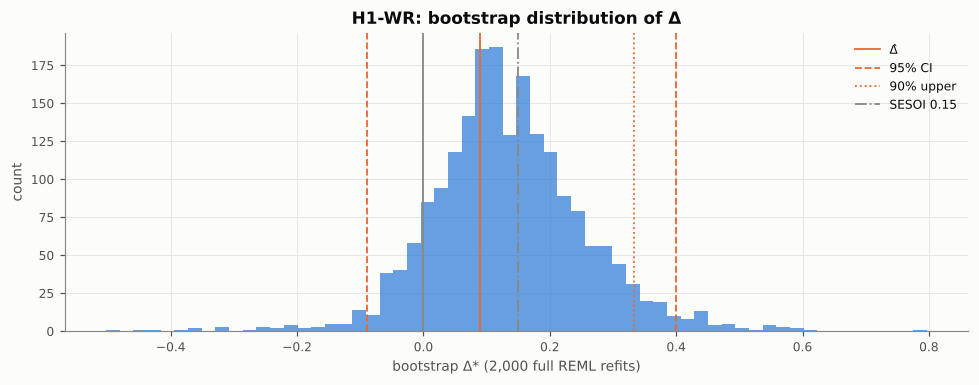

In [3]:
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.hist(boot, bins=60, color=style.SERIES[0], alpha=0.7)
for v, ls, lab in [(P['delta'], '-', 'Δ̂'), (P['ci95_percentile'][0], '--', '95% CI'), (P['ci95_percentile'][1], '--', None),
                   (P['ci90_percentile'][1], ':', '90% upper'), (0.15, '-.', 'SESOI 0.15'), (0, '-', None)]:
    ax.axvline(v, ls=ls, color=style.MUTED if v in (0, 0.15) else style.SERIES[1], lw=1.2, label=lab)
ax.set_xlabel('bootstrap Δ* (2,000 full REML refits)'); ax.set_ylabel('count'); ax.legend(); ax.set_title('H1-WR: bootstrap distribution of Δ')
fig.tight_layout(); fig.savefig(ROOT / 'reports/figures/h1_wr_bootstrap.png', dpi=150); plt.show()

## 2. Sample and observations per context

In [4]:
S = R['sample']
print('players', S['players'], '| plays', S['plays'], '| team-seasons', R['diagnostics']['team_seasons'],
      '(single-player team-seasons', R['diagnostics']['team_seasons_single_player'], ')')
display(pl.DataFrame(S['by_context'])); display(pl.DataFrame(S['plays_per_player_context'])); pl.DataFrame(S['seasons'])

players 57 | plays 19960 | team-seasons 71 (single-player team-seasons 36 )


ctx,plays,players
str,i64,i64
"""deep""",9961,57
"""short""",9999,57


ctx,min,median,max
str,i64,f64,i64
"""deep""",47,141.0,575
"""short""",31,144.0,528


season,plays,players
i64,i64,i64
2023,3851,24
2024,7245,39
2025,8864,51


## 3. Convergence and diagnostics

In [5]:
D = R['diagnostics']; Bt = R['bootstrap']
print(json.dumps({k: D[k] for k in ('converged', 'sigma_b', 'corr_b', 's2_team', 's2_resid', 'fixed_effect_columns', 'reliability_player_context_mean')}, indent=1))
print('bootstrap refits OK:', Bt['n_ok'], 'failed:', Bt['n_failed'], '| boot mean', round(Bt['mean'], 4), 'sd', round(Bt['sd'], 4),
      '| median − Δ̂', round(Bt['median_minus_estimate'], 4))
print('season-forward fit:', P['season_forward'])
print('seconds:', R['seconds'])

{
 "converged": true,
 "sigma_b": [
  [
   0.0352660879317651,
   0.03014569235375155
  ],
  [
   0.03014569235375155,
   0.060038473583990934
  ]
 ],
 "corr_b": 0.6551365035980283,
 "s2_team": 0.009886173131091958,
 "s2_resid": [
  0.762963011545771,
  1.4527898859634922
 ],
 "fixed_effect_columns": 56,
 "reliability_player_context_mean": [
  0.848060693193305,
  0.8196908703629329
 ]
}
bootstrap refits OK: 2000 failed: 0 | boot mean 0.1341 sd 0.1225 | median − Δ̂ 0.035
season-forward fit: {'delta_2025': 0.21903877251676285, 'rho_2025': [0.6682960633818348, 0.44925729086507193], 'n_players_2025': 46, 'n_plays_2025': 8745, 'converged': True}
seconds: {'primary': 656.2705085277557, 'total': 679.0521078109741}


## 4. Registered accompanying reports (none affects the decision)

In [6]:
E = R['effect_size']; M = R['cross_check_moment']; Bc = R['bca']; By = R['bayes_sensitivity']
print('BCa 95%:', [round(v, 4) for v in Bc['ci']['0.95']], '| BCa 90%:', [round(v, 4) for v in Bc['ci']['0.9']], '| z0', round(Bc['z0'], 3), 'a', round(Bc['acceleration'], 4))
print('raw slopes (yd/s of game speed per 0.25 yd/s combine peak): deep %.3f, short %.3f' % tuple(E['raw_slope_per_0_25_yds']))
display(pl.DataFrame([dict(R_x=k, **v) for k, v in E['disattenuated'].items()]))
print('moment cross-check (spec §1.2, never decisive): Δ =', round(M['delta'], 4), 'ρ =', [round(v, 4) for v in M['rho']], '| disagrees by > SE/2:', M['disagrees_by_more_than_half_se'])
print('Bayesian sensitivity (prior N(0, 0.15²)): posterior mean %.3f, sd %.3f, P(Δ>0) %.3f, P(Δ>0.15) %.3f' %
      (By['posterior_mean'], By['posterior_sd'], By['p_delta_gt_0'], By['p_delta_gt_sesoi']))

BCa 95%: [-0.2841, 0.2827] | BCa 90%: [-0.1789, 0.2352] | z0 -0.368 a 0.0132
raw slopes (yd/s of game speed per 0.25 yd/s combine peak): deep 0.110, short 0.113


R_x,rho_deep,rho_short,delta
str,f64,f64,f64
"""registered_pooled""",0.579681,0.489137,0.090544
"""within_WR_D3""",0.593997,0.501216,0.09278


moment cross-check (spec §1.2, never decisive): Δ = 0.0717 ρ = [0.5265, 0.4547] | disagrees by > SE/2: False
Bayesian sensitivity (prior N(0, 0.15²)): posterior mean 0.054, sd 0.095, P(Δ>0) 0.715, P(Δ>0.15) 0.156


## 5. Interpretation of the confirmatory result

See `research_notes/h1_wr_confirmatory_results.md`.

---
# Part B: registered sensitivity analyses (they do not re-decide H1)

From `scripts/run_h1_wr_robustness.py`. Notes: `h1_wr_robustness_results.md` and `h1_wr_negative_controls.md`.

In [7]:
ROB = ROOT / 'experiments/h1_wr_robustness' / (ROOT / 'experiments/h1_wr_robustness/LATEST').read_text().strip()
RB = json.load(open(ROB / 'robustness.json')); DG = json.load(open(ROB / 'bootstrap_diagnostics.json'))
print('robustness run', ROB.name, '| code commit', RB['code_commit'], '| seeds', RB['seeds'])
lab = {'R1': 'R1 eligibility >= 50', 'R2': 'R2 eligibility >= 200', 'R3': 'R3 without time-to-throw', 'R4': 'R4 REG + POST',
       'R8': 'R8 mean-of-attempts peak', 'R9': 'R9 IN/CROSS as short', 'R11': 'R11 + playing time',
       'R12_class_2023': 'R12 class 2023', 'R12_class_2024': 'R12 class 2024', 'R12_class_2025': 'R12 class 2025 (new players)',
       'R13_2023_2024': 'R13 2023+2024 fit', 'R13_2025': 'R13 2025 fit'}
rows = [dict(check='PRIMARY (confirmatory)', delta=P['delta'], ci_lo=P['ci95_percentile'][0], ci_hi=P['ci95_percentile'][1], se=P['se_boot'], players=S['players'], plays=S['plays'])]
rows += [dict(check=lab[k], delta=v['delta'], ci_lo=v['ci_lo'], ci_hi=v['ci_hi'], se=v['se_boot'], players=v['players'], plays=v['plays']) for k, v in RB['registered'].items()]
C6 = RB['R6_ceiling']; rows.append(dict(check='R6 ceiling-robust outcome', delta=C6['delta'], ci_lo=C6['ci'][0], ci_hi=C6['ci'][1], se=C6['se_boot'], players=C6['players'], plays=None))
SEN = pl.DataFrame(rows, infer_schema_length=None); SEN

robustness run 20261121T233918Z | code commit a18a1d8a2b3b78fe83376ac8e8893362621155fd | seeds {'R1': 5001, 'R2': 5002, 'R3': 5003, 'R4': 5004, 'R6': 5006, 'R6_inner': 5106, 'R7': 5007, 'R7_cv': 5107, 'R8': 5008, 'R9': 5009, 'R11': 5011, 'R12_2023': 5012, 'R12_2024': 5112, 'R12_2025': 5212, 'R13_2324': 5013, 'R13_2025': 5113, 'N1': 6001}


check,delta,ci_lo,ci_hi,se,players,plays
str,f64,f64,f64,f64,i64,i64
"""PRIMARY (confirmatory)""",0.089954,-0.088646,0.400058,0.122493,57,19960
"""R1 eligibility >= 50""",0.081699,-0.101356,0.343744,0.120541,61,20162
"""R2 eligibility >= 200""",0.118922,-0.176854,0.44885,0.15257,45,18602
"""R3 without time-to-throw""",0.099511,-0.160327,0.373272,0.130948,57,19960
"""R4 REG + POST""",0.080775,-0.119452,0.392742,0.129827,57,20871
"""R8 mean-of-attempts peak""",0.11031,-0.081105,0.409033,0.128233,57,19960
"""R9 IN/CROSS as short""",0.0727,-0.148395,0.255759,0.10578,57,26030
"""R11 + playing time""",0.116022,-0.081937,0.413049,0.126933,57,19960
"""R13 2023+2024 fit""",-0.051204,-0.953348,0.460284,0.332136,40,11088


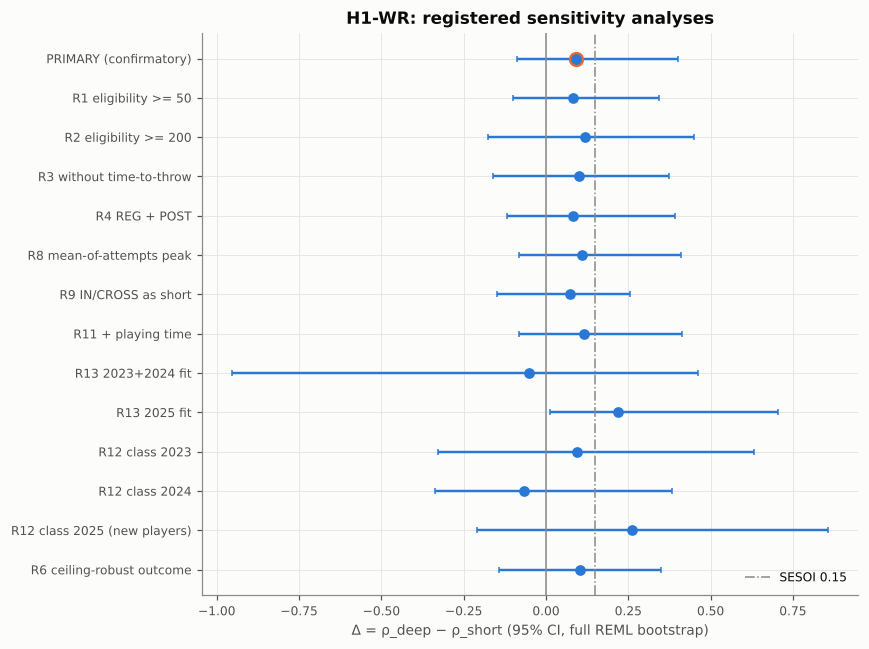

In [8]:
fig, ax = plt.subplots(figsize=(8, 6))
yy = np.arange(SEN.height)[::-1]
ax.errorbar(SEN['delta'], yy, xerr=[SEN['delta'] - SEN['ci_lo'], SEN['ci_hi'] - SEN['delta']], fmt='o', color=style.SERIES[0], capsize=2)
ax.plot(SEN['delta'][0], yy[0], 'o', color=style.SERIES[1], ms=9)
ax.axvline(0, color=style.MUTED, lw=1); ax.axvline(0.15, color=style.MUTED, lw=1, ls='-.', label='SESOI 0.15')
ax.set_yticks(yy, SEN['check']); ax.set_xlabel('Δ = ρ_deep − ρ_short (95% CI, full REML bootstrap)'); ax.legend(loc='lower right')
ax.set_title('H1-WR: registered sensitivity analyses')
fig.tight_layout(); fig.savefig(ROOT / 'reports/figures/h1_wr_sensitivity_forest.png', dpi=150); plt.show()

R5 leave-one-team-out: 29 teams, delta range 0.035 to 0.125
R7 spline: avg derivative deep 0.127 short 0.147, diff -0.020, 95% CI [-0.100, 0.041] | linear slope diff -0.004
R7 player-grouped CV (10x20): RMSE linear 1.0824, spline 1.0845, spline better in 0/20 repeats


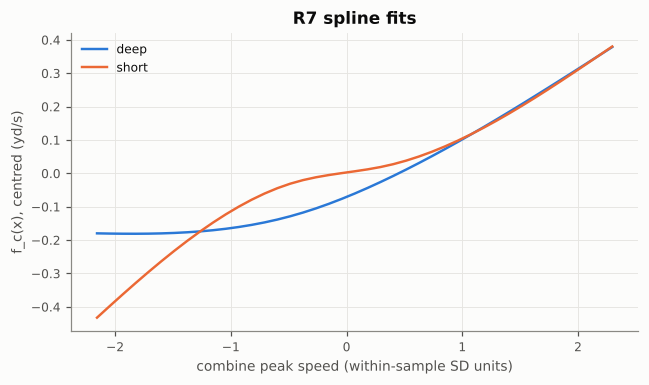

elig_h1,n,mean_forty,sd_forty,mean_peak,mean_round,share_undrafted
bool,i64,f64,f64,f64,f64,f64
false,37,4.485135,0.088369,11.10221,5.4,0.459459
true,57,4.465088,0.089963,11.123031,3.78,0.122807


In [9]:
lo = np.array([x['delta'] for x in RB['R5_leave_one_team_out']])
print('R5 leave-one-team-out: %d teams, delta range %.3f to %.3f' % (len(lo), lo.min(), lo.max()))
SP = RB['R7_spline']; cvd = pl.DataFrame(SP['cv'])
sb = np.load(ROB / 'bootstraps.npz')['spline']
print('R7 spline: avg derivative deep %.3f short %.3f, diff %.3f, 95%% CI [%.3f, %.3f] | linear slope diff %.3f' %
      (SP['avg_deriv'][0], SP['avg_deriv'][1], SP['diff'], *np.nanpercentile(sb[:, 2], [2.5, 97.5]), SP['linear_slope_diff']))
print('R7 player-grouped CV (10x20): RMSE linear %.4f, spline %.4f, spline better in %d/20 repeats' %
      (cvd['rmse_linear'].mean(), cvd['rmse_spline'].mean(), int((cvd['rmse_spline'] < cvd['rmse_linear']).sum())))
fig, ax = plt.subplots(figsize=(6, 3.6))
g = np.array(SP['grid']); cu = np.array(SP['curves'])
for c, name in enumerate(['deep', 'short']):
    ax.plot(g, cu[c] - cu[c].mean(), color=style.SERIES[c], label=name)
ax.set_xlabel('combine peak speed (within-sample SD units)'); ax.set_ylabel('f_c(x), centred (yd/s)'); ax.legend(); ax.set_title('R7 spline fits')
fig.tight_layout(); plt.show()
display(pl.DataFrame(RB['R14_selection']))

## Negative control N1: context labels permuted within player (registered)
N2 (OL contrast) and N3 (WR short-route β_P) belong to H5 and H2, which are deferred.

N1: 500 permutations, mean 0.0032 (MC SE 0.0024), SD 0.053, 2.5/97.5% [-0.101, 0.111]


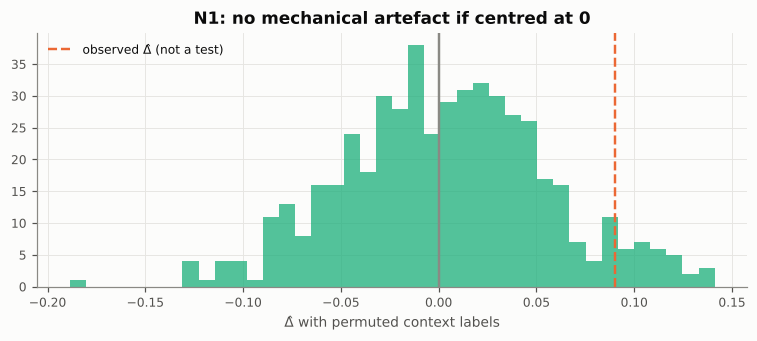

In [10]:
pv = np.array([x['delta'] for x in RB['N1_permutation']])
print('N1: %d permutations, mean %.4f (MC SE %.4f), SD %.3f, 2.5/97.5%% [%.3f, %.3f]' % (len(pv), pv.mean(), pv.std() / np.sqrt(len(pv)), pv.std(), *np.percentile(pv, [2.5, 97.5])))
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(pv, bins=40, color=style.SERIES[2], alpha=0.75); ax.axvline(0, color=style.MUTED); ax.axvline(P['delta'], color=style.SERIES[1], ls='--', label='observed Δ̂ (not a test)')
ax.set_xlabel('Δ̂ with permuted context labels'); ax.legend(); ax.set_title('N1: no mechanical artefact if centred at 0')
fig.tight_layout(); plt.show()

---
# Part C: exploratory diagnostics (bootstrap intervals and the Wald check)
These diagnostics explain the intervals. **The registered percentile interval remains primary.** See `h1_wr_bootstrap_diagnostics.md`.

In [11]:
print(json.dumps({k: DG[k] for k in ('distribution', 'bca')}, indent=1)[:2500])
display(pl.DataFrame([dict(variant=k, level_lo=v['levels'][0], level_hi=v['levels'][1], lo=v['interval'][0], hi=v['interval'][1]) for k, v in DG['bca']['decomposition'].items()]))
display(pl.DataFrame(DG['phase4_bootstrap_world']))

{
 "distribution": {
  "B": 2000,
  "mean": 0.13405341374984897,
  "median": 0.1249124055322578,
  "sd": 0.12249346789396932,
  "skewness": 0.10045925533903008,
  "excess_kurtosis": 2.341371716820377,
  "share_below_estimate": 0.3565,
  "iqr_sd": 0.10264653967863052,
  "tails": {
   "lower_2_5_minus_est": -0.17859977361755408,
   "upper_97_5_minus_est": 0.3101040123434172
  }
 },
 "bca": {
  "z0": -0.36782999744835626,
  "acceleration": 0.013179772441784728,
  "decomposition": {
   "full_bca": {
    "levels": [
     0.004315509657427503,
     0.895881739746156
    ],
    "interval": [
     -0.2841217120913321,
     0.28267016022095665
    ]
   },
   "bias_correction_only": {
    "levels": [
     0.0035128463463633304,
     0.8895812137694217
    ],
    "interval": [
     -0.31017669627607425,
     0.27816487673616963
    ]
   },
   "acceleration_only": {
    "levels": [
     0.02802740067590197,
     0.9778866619734264
    ],
    "interval": [
     -0.07758312680677903,
     0.40582222

variant,level_lo,level_hi,lo,hi
str,f64,f64,f64,f64
"""full_bca""",0.004316,0.895882,-0.284122,0.28267
"""bias_correction_only""",0.003513,0.889581,-0.310177,0.278165
"""acceleration_only""",0.028027,0.977887,-0.077583,0.405822
"""percentile""",0.025,0.975,-0.088646,0.400058


scenario,truth,reml_bias,boot_median_shift,implied_z0,sampling_sd,boot_sd,percentile_coverage,percentile_reject,percentile_miss_high,bca_type_coverage,bca_type_reject,bca_type_miss_high
i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
1,0.0,0.004769,0.013566,-0.118085,0.111889,0.159247,0.9925,0.0075,0.0,0.9975,0.0025,0.0
2,0.0,0.001988,-0.00411,0.030711,0.113835,0.172769,1.0,0.0,0.0,1.0,0.0,0.0
3,0.099348,-0.008561,0.030551,-0.250113,0.110779,0.158536,0.9925,0.0725,0.0,0.99,0.0,0.01
4,0.198696,-0.000431,0.042198,-0.36716,0.112767,0.14728,0.9575,0.4475,0.0,0.9875,0.115,0.0125
5,0.347718,-0.005013,0.054982,-0.486659,0.107268,0.146641,0.9475,0.935,0.0,0.9675,0.455,0.0325
6,0.0,-0.003047,0.020063,-0.149068,0.103746,0.170975,1.0,0.0,0.0,1.0,0.0,0.0
7,0.0,0.01887,0.042639,-0.288453,0.11911,0.196397,0.995,0.005,0.0,1.0,0.0,0.0


In [12]:
J = DG['jackknife']; print('player jackknife: range', [round(v, 3) for v in J['range']], '| max change', round(J['max_abs_change'], 3), '| sign changes', J['sign_changes'], '| jackknife SE', round(J['sd_jackknife_se'], 3))
display(pl.DataFrame(J['top5_influence']))
for k in ('leave_one_team_out', 'leave_one_team_season_out'):
    print(k, {kk: (round(vv, 3) if isinstance(vv, float) else vv) for kk, vv in DG[k].items()})
W = DG['wald']; print('Wald: delta %.4f, SE %.4f, 95%% CI [%.3f, %.3f], 90%% CI [%.3f, %.3f]; criterion reproduced to %.1e; Hessian eigen [%.1f, %.1f]' %
      (W['delta'], W['se'], *W['ci95'], *W['ci90'], W['criterion_reproduced_abs_diff'], W['hessian_min_eig'], W['hessian_max_eig']))
cal = ROOT / 'experiments/h1_wr_robustness_dev/wald_calibration.parquet'
if cal.exists():
    wc = pl.read_parquet(cal)
    display(wc.group_by('scenario').agg(pl.len().alias('reps'), pl.col('delta').std().alias('sd_delta'), pl.col('se').mean().alias('mean_wald_se'),
        ((pl.col('delta') - pl.col('truth')).abs() <= 1.96 * pl.col('se')).mean().alias('coverage'), ((pl.col('delta') - 1.96 * pl.col('se')) > 0).mean().alias('reject')).sort('scenario'))

player jackknife: range [0.051, 0.121] | max change 0.039 | sign changes 0 | jackknife SE 0.092


rank,influence,delta_without
i64,f64,f64
1,2.167279,0.051086
2,-1.774625,0.121477
3,1.67026,0.059961
4,1.614186,0.060963
5,-1.29463,0.112906


leave_one_team_out {'clusters': 29, 'min': 0.035, 'max': 0.125, 'max_abs_change': 0.055, 'sign_changes': 0, 'cluster_jackknife_se': 0.103, 'all_converged': True}
leave_one_team_season_out {'clusters': 71, 'min': 0.045, 'max': 0.123, 'max_abs_change': 0.045, 'sign_changes': 0, 'cluster_jackknife_se': 0.104, 'all_converged': True}
Wald: delta 0.0900, SE 0.1042, 95% CI [-0.114, 0.294], 90% CI [-0.081, 0.261]; criterion reproduced to 7.3e-12; Hessian eigen [63.1, 39583.2]


scenario,reps,sd_delta,mean_wald_se,coverage,reject
i64,u32,f64,f64,f64,f64
1,100,0.113218,0.108306,0.95,0.03
4,100,0.117533,0.104479,0.93,0.52


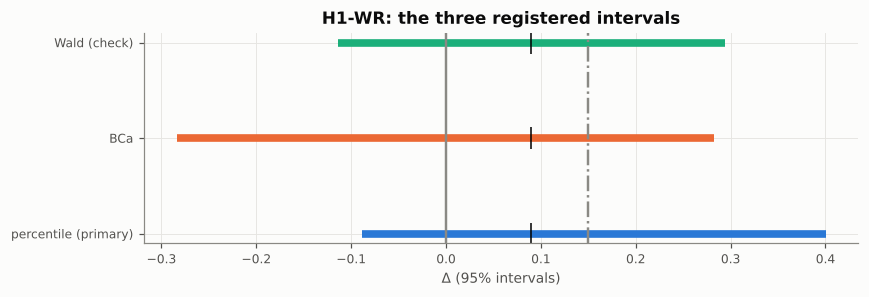

In [13]:
fig, ax = plt.subplots(figsize=(8, 2.8))
iv = [('percentile (primary)', P['ci95_percentile']), ('BCa', DG['bca']['decomposition']['full_bca']['interval']), ('Wald (check)', W['ci95'])]
for k, (name, (lo_, hi_)) in enumerate(iv):
    ax.plot([lo_, hi_], [k, k], lw=5, color=style.SERIES[k], solid_capstyle='butt'); ax.plot(P['delta'], k, 'k|', ms=14)
ax.axvline(0, color=style.MUTED); ax.axvline(0.15, color=style.MUTED, ls='-.')
ax.set_yticks(range(3), [n for n, _ in iv]); ax.set_xlabel('Δ (95% intervals)'); ax.set_title('H1-WR: the three registered intervals')
fig.tight_layout(); fig.savefig(ROOT / 'reports/figures/h1_wr_intervals.png', dpi=150); plt.show()